In [28]:
from langgraph.graph import StateGraph, END, START
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
from langgraph.checkpoint.memory import MemorySaver

In [29]:
load_dotenv()

True

In [30]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=os.getenv("GROQ_API_KEY"),
    temperature=0,
)

In [31]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [32]:
def chat_node(state: ChatState):
    # take user query from state
    message = state['messages']
    # send to llm
    resp = llm.invoke(message)
    # response store state
    return {'messages': [resp]}

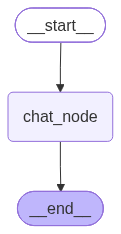

In [33]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

# add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer=checkpoint)
chatbot

In [36]:
thread_id = "1"
while True: 
    user_message = input("Type Here: ")

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    resp = chatbot.invoke({'messages' : [HumanMessage(content=user_message)]}, config=config)['messages'][-1].content

    print("AI BOT:", resp)

chatbot.get_state(config=config)


User: hi
AI BOT: Hello, Mahima! How can I help you today?
User: i have loads of work to do 
AI BOT: Sounds like a busy day ahead! 🚀

To help you tackle that mountain of tasks, let’s break it down:

| Step | What to Do | Why It Helps |
|------|------------|--------------|
| 1️⃣ **List everything** | Write down every task, no matter how small. | Gives you a clear picture and prevents forgetting anything. |
| 2️⃣ **Prioritize** | Use the Eisenhower Matrix: <br>• **Urgent & Important** (do first) <br>• **Important, not urgent** (schedule) <br>• **Urgent, not important** (delegate if possible) <br>• **Neither** (consider dropping) | Focuses energy where it matters most. |
| 3️⃣ **Chunk & Time‑block** | Group similar tasks (e.g., emails, reports, calls) and assign 25‑30 min blocks (Pomodoro). | Reduces context‑switching and keeps momentum. |
| 4️⃣ **Set micro‑deadlines** | Give each block a specific end time. | Creates a sense of urgency and prevents procrastination. |
| 5️⃣ **Use a tool** |

StateSnapshot(values={'messages': [HumanMessage(content='who is narendra modi', additional_kwargs={}, response_metadata={}, id='d4eec480-5b9c-4b92-a197-357f4a22ca7a'), AIMessage(content='**Narendra Modi** (born\u202f17\u202fSeptember\u202f1950) is an Indian politician who has served as the **Prime Minister of India since 26\u202fMay\u202f2014**. He is a senior leader of the **Bharatiya Janata Party (BJP)** and previously served as the **Chief Minister of Gujarat** from 2001 to 2014. Modi’s tenure as prime minister has been marked by major economic reforms (e.g., the Goods and Services Tax, demonetization), a focus on digital infrastructure, and a push for a “Make\u202fIn\u202fIndia” manufacturing agenda. He has also overseen significant foreign‑policy initiatives, such as the U.S.–India strategic partnership and the “Act East” policy. His leadership style and policies have drawn both strong support for modernization and criticism over issues such as religious polarization, press freedo